<a href="https://colab.research.google.com/github/velezverespeter/energy-trading-risk/blob/main/notebooks/01_data_preparation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 01 Data preparation

This notebook loads hourly day-ahead electricity prices for Slovenia, checks their quality and builds the daily price series used in the risk analysis.

**Input:** `ember_si_hourly_prices.csv` (Ember, based on the ENTSO-E Transparency Platform)
**Output:** `si_prices_clean.csv` (hourly), `si_prices_daily.csv` (daily base and peak prices), `prices.png`

When running in Google Colab, upload `ember_si_hourly_prices.csv` from the `data/` folder first.

## 1. Load raw data

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("ember_si_hourly_prices.csv")
df.head()

,Country,ISO3 Code,Datetime (UTC),Datetime (Local),Price (EUR/MWhe)
0,Slovenia,SVN,2015-01-01 00:00:00,2015-01-01 01:00:00,23.25
1,Slovenia,SVN,2015-01-01 01:00:00,2015-01-01 02:00:00,22.20
2,Slovenia,SVN,2015-01-01 02:00:00,2015-01-01 03:00:00,19.56
3,Slovenia,SVN,2015-01-01 03:00:00,2015-01-01 04:00:00,18.88
4,Slovenia,SVN,2015-01-01 04:00:00,2015-01-01 05:00:00,18.39


In [2]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 103146 entries, 0 to 103145
Data columns (total 5 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   Country           103146 non-null  object 
 1   ISO3 Code         103146 non-null  object 
 2   Datetime (UTC)    103146 non-null  object 
 3   Datetime (Local)  103146 non-null  object 
 4   Price (EUR/MWhe)  101730 non-null  float64
dtypes: float64(1), object(4)
memory usage: 3.9+ MB


The full file covers 2015–2026. Missing prices are all in May and June 2026, outside the analysed period.

## 2. Select columns and period

Only the UTC timestamp and the price are kept. UTC has no daylight-saving shifts, so every day has exactly 24 hours.

In [3]:
df = df[["Datetime (UTC)", "Price (EUR/MWhe)"]]
df.columns = ["datetime", "price"]

df["datetime"] = pd.to_datetime(df["datetime"])

df = df[(df["datetime"] >= "2021-01-01") & (df["datetime"] < "2026-01-01")]

df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 43824 entries, 52608 to 96431
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype         
---  ------    --------------  -----         
 0   datetime  43824 non-null  datetime64[ns]
 1   price     43824 non-null  float64       
dtypes: datetime64[ns](1), float64(1)
memory usage: 1.0 MB


## 3. Data quality checks

The period should contain 43,824 hours (5 × 8,760 plus 24 hours for 29 February 2024), with no duplicates, gaps or missing prices.

In [4]:
print("Duplicate hours:", df["datetime"].duplicated().sum())

all_hours = pd.date_range("2021-01-01 00:00", "2025-12-31 23:00", freq="h")
missing_hours = all_hours.difference(df["datetime"])
print("Missing hours:  ", len(missing_hours))

print("Missing prices: ", df["price"].isna().sum())

Duplicate hours: 0
Missing hours:   0
Missing prices:  0


In [5]:
df["price"].describe()

count    43824.000000
mean       137.943440
std        106.948662
min       -500.000000
25%         77.090000
50%        108.000000
75%        166.512500
max       1022.270000
Name: price, dtype: float64

## 4. Extreme and negative prices

Times below are in UTC. The lowest price, −500 EUR/MWh at 12:00 UTC on 2 July 2023, corresponds to 14:00 local time.

In [6]:
print("Lowest prices:")
print(df.nsmallest(5, "price"))
print()
print("Highest prices:")
print(df.nlargest(5, "price"))

Lowest prices:
                 datetime   price
74508 2023-07-02 12:00:00 -500.00
90804 2025-05-11 12:00:00 -126.46
90803 2025-05-11 11:00:00 -126.40
90563 2025-05-01 11:00:00 -124.77
90780 2025-05-10 12:00:00 -119.93

Highest prices:
                 datetime    price
84689 2024-08-29 17:00:00  1022.27
84785 2024-09-02 17:00:00   991.29
84784 2024-09-02 16:00:00   958.21
67170 2022-08-30 18:00:00   879.29
67145 2022-08-29 17:00:00   871.00


In [7]:
negative = df[df["price"] < 0]
negative.groupby(negative["datetime"].dt.year).size()

datetime
2021     23
2023     96
2024    218
2025    268
dtype: int64

## 5. Local time and peak hours

Peak hours are defined in local time as weekdays from 08:00 to 20:00, so timestamps are converted from UTC to Europe/Ljubljana.

In [8]:
df["local"] = df["datetime"].dt.tz_localize("UTC").dt.tz_convert("Europe/Ljubljana")

df["date"] = df["local"].dt.date
df["hour"] = df["local"].dt.hour
df["weekday"] = df["local"].dt.dayofweek

df["is_peak"] = (df["weekday"] < 5) & (df["hour"] >= 8) & (df["hour"] < 20)
df["is_peak"].value_counts()

is_peak
False    28176
True     15648
Name: count, dtype: int64

## 6. Daily base and peak prices

Base is the average over all hours of a local day, peak the average over peak hours. Weekends have no peak hours, so their peak value is empty.

Converting to local time creates a one-hour "day" on 1 January 2026 (the last UTC hour of 2025), which is removed. The first day, 1 January 2021, has 23 hours, which has a negligible effect.

In [9]:
base = df.groupby("date")["price"].mean()
peak = df[df["is_peak"]].groupby("date")["price"].mean()

daily = pd.DataFrame({"base": base, "peak": peak})
daily.index = pd.to_datetime(daily.index)
daily = daily[daily.index < "2026-01-01"]

print("Days:", len(daily))
daily.head(10)

Days: 1826


,base,peak
date,,
2021-01-01,46.405217,49.247500
2021-01-02,33.857917,NaN
2021-01-03,40.925000,NaN
2021-01-04,50.570000,61.125000
2021-01-05,57.294583,66.015833
2021-01-06,47.407083,61.815000
2021-01-07,72.190417,86.690833
2021-01-08,77.922500,99.563333
2021-01-09,52.297917,NaN


## 7. Chart and export

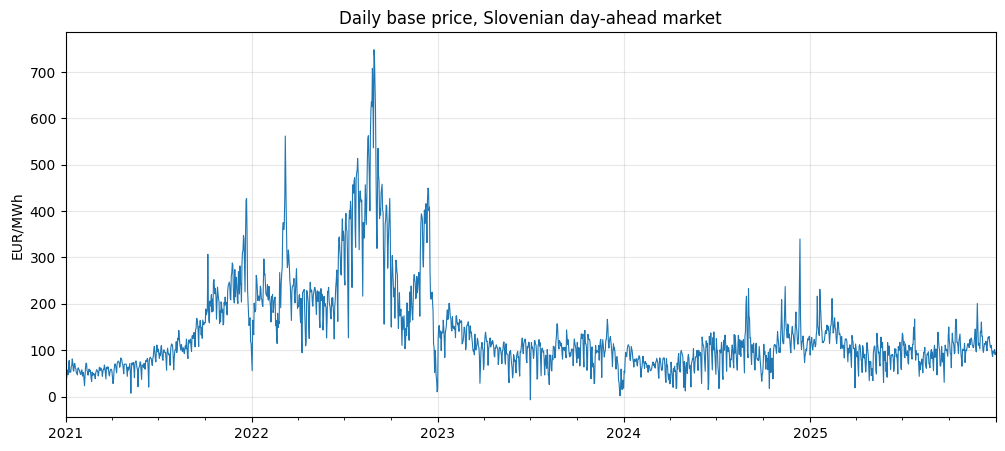

In [10]:
daily["base"].plot(figsize=(12, 5), linewidth=0.8)
plt.title("Daily base price, Slovenian day-ahead market")
plt.ylabel("EUR/MWh")
plt.xlabel("")
plt.grid(alpha=0.3)
plt.savefig("prices.png", dpi=150, bbox_inches="tight")
plt.show()

daily.to_csv("si_prices_daily.csv")
df.to_csv("si_prices_clean.csv", index=False)